In [9]:
from datasets import load_dataset
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Load the training dataset in streaming mode
dataset = load_dataset(
    "fancyzhx/amazon_polarity",
    split="train",
    streaming=True
)

# Shuffle and select 10,000 reviews
sample = dataset.shuffle(
    seed=42,
    buffer_size=10000
).take(10000)

# Convert to Pandas DataFrame
df = pd.DataFrame(list(sample))

# Create dataset directory
os.makedirs("../data/raw", exist_ok=True)

# Save as CSV
df.to_csv(
    "../data/raw/customer_feedback.csv",
    index=False
)

print("Dataset downloaded successfully!")
print("Total records:", len(df))
print(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset downloaded successfully!
Total records: 10000
   label                                              title  \
0      0                                   Defected Product   
1      0                               problem with product   
2      0  can't handle power losses - active ports fry o...   
3      0                      Looks great, poor performance   
4      1                             perfect for loose teas   

                                             content  
0  I purchased this product because my cat prefer...  
1  The product I received came in time but was da...  
2  I have just fried my second of this model. Whe...  
3  I bought this high end kettle thinking I would...  
4  Looked a long time for this. Careful- it holds...  


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 10000
Number of columns: 3

Column names:
['label', 'title', 'content']


In [11]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    10000 non-null  int64
 1   title    10000 non-null  str  
 2   content  10000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 4.3 MB


In [12]:
print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values:
label      0
title      0
content    0
dtype: int64

Total missing values: 0


In [13]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [14]:
sentiment_counts = df['label'].value_counts().sort_index()

print("Sentiment Distribution:")
print(sentiment_counts)

print("\nSentiment Percentages:")
print(df['label'].value_counts(normalize=True) * 100)

Sentiment Distribution:
label
0    5006
1    4994
Name: count, dtype: int64

Sentiment Percentages:
label
0    50.06
1    49.94
Name: proportion, dtype: float64


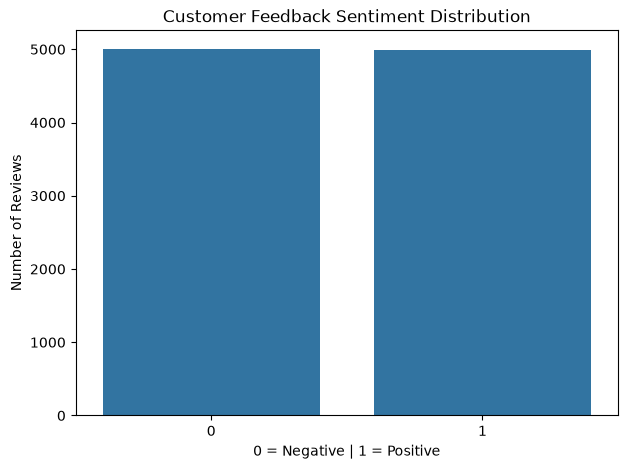

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='label')

plt.title("Customer Feedback Sentiment Distribution")
plt.xlabel("0 = Negative | 1 = Positive")
plt.ylabel("Number of Reviews")

plt.show()

### Dataset Observation – Sentiment Distribution

The dataset contains 10,000 customer reviews.

- 5,000 Negative reviews (50%)
- 5,000 Positive reviews (50%)

The dataset is balanced across both sentiment classes.
This is beneficial for training a sentiment classification model
because neither class dominates the dataset.

The dataset currently supports binary sentiment classification.
Neutral sentiment will be explored as a future enhancement.

In [17]:
df['review_length'] = df['content'].astype(str).apply(len)

print("Review Length Statistics:")
print(df['review_length'].describe())

Review Length Statistics:
count    10000.000000
mean       398.554000
std        231.840755
min         59.000000
25%        203.000000
50%        349.000000
75%        553.000000
max       1006.000000
Name: review_length, dtype: float64


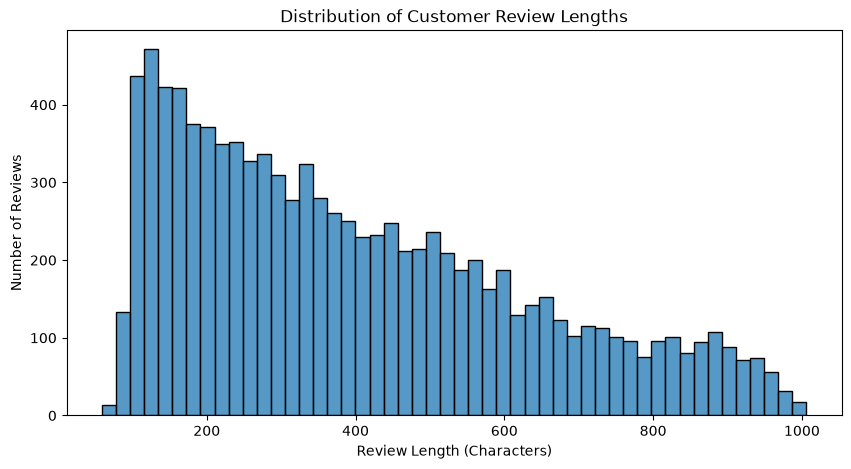

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='review_length',
    bins=50
)

plt.title("Distribution of Customer Review Lengths")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")

plt.show()


### Review Length Analysis

The customer feedback dataset contains 10,000 reviews.

Key observations:

- Average review length: approximately 399 characters.
- Median review length: 349 characters.
- Minimum review length: 59 characters.
- Maximum review length: 1,006 characters.
- Most reviews contain between 100 and 400 characters.

The distribution is right-skewed, indicating that a smaller
number of customers provide longer and more detailed feedback.

This analysis will help us determine appropriate text
tokenization and sequence length settings for BERT.


In [19]:
# Display 5 negative reviews

negative_reviews = df[df['label'] == 0]

for index, row in negative_reviews.head(5).iterrows():
    print("Title:", row['title'])
    print("Review:", row['content'])
    print("-" * 100)

Title: Defected Product
Review: I purchased this product because my cat prefers to drink from running water source. I bought it to replace a fountain we had for three years. This one did not even last a few months. At first I was pleased with the noise level (nice and quiet) but within a month the water stopped shooting out of the mouth. I believe the motor is defected. The only way it works if you remove the fish and with cover. Not sure if this is an isolated case but I would be wary of purchasing the Cats Rule Fountains. Too bad because they are cute!
----------------------------------------------------------------------------------------------------
Title: problem with product
Review: The product I received came in time but was damaged. The latch did not work and a divider was broken as well.
----------------------------------------------------------------------------------------------------
Title: can't handle power losses - active ports fry on powerloss
Review: I have just fried 

In [20]:
# Display 5 positive reviews

positive_reviews = df[df['label'] == 1]

for index, row in positive_reviews.head(5).iterrows():
    print("Title:", row['title'])
    print("Review:", row['content'])
    print("-" * 100)

Title: perfect for loose teas
Review: Looked a long time for this. Careful- it holds a lot and you may accidently brew a really strong cup! Wish I had about 4 more. Will buy again soon.
----------------------------------------------------------------------------------------------------
Title: Hole in one
Review: This games is great. I am a new fan of sports games. I have been playing this with other guys at work (I have a great job) and we have been rocking the house taking turns and rooting each other on. Even the girls get into watching.You can create cool dudes or hot chics with funny voices. The animation is basic with the characters- but the golfing is great and challenging - but not incredibly hard to learn.Putting takes a little time to perfect but you wouldn't want a game that is going to make everything easy, would you? Yeah, there are some hard parts- get over it.
----------------------------------------------------------------------------------------------------
Title: Great